# Кластеризация ЕГЭ (8.5 если сделаны все задачи)

Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans as KM, DBSCAN as DB
from sklearn.datasets import make_circles as mc, make_moons as mm, make_blobs as mb
from sklearn.preprocessing import StandardScaler as SS

d = []
for i in range(6):
    a = pd.read_excel(str(i) + ('.xls' if i < 2 else '.xlsx'), header=None)
    a = a.apply(pd.to_numeric, errors='coerce').dropna().to_numpy()
    d.append(a)

/tmp/ipykernel_35006/502754416.py:10: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  a = pd.read_excel(str(i) + ('.xls' if i < 2 else '.xlsx'), header=None)
/tmp/ipykernel_35006/502754416.py:10: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  a = pd.read_excel(str(i) + ('.xls' if i < 2 else '.xlsx'), header=None)


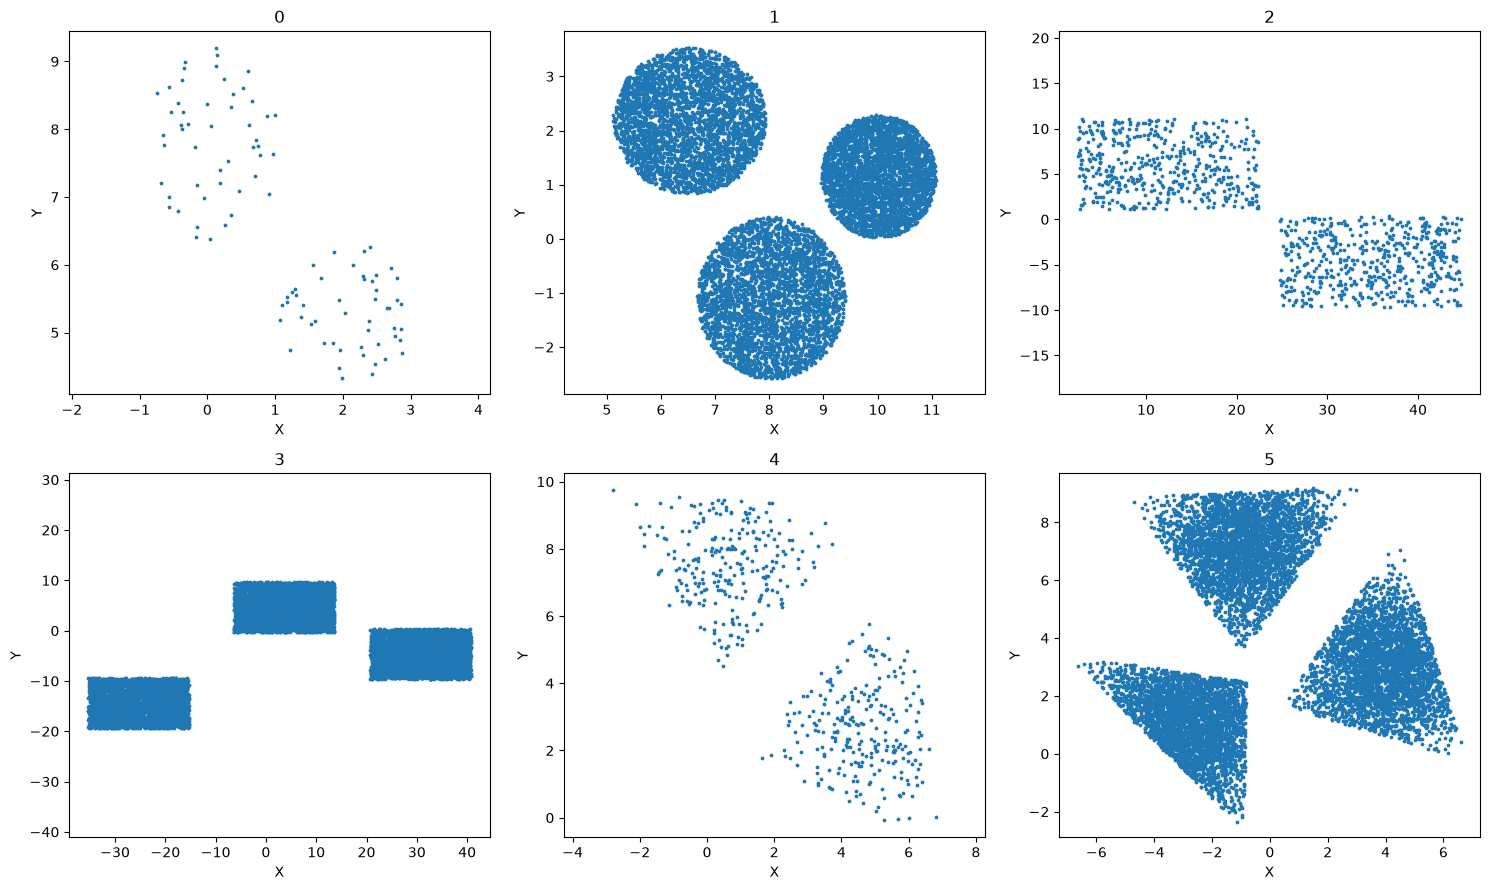

In [2]:
plt.figure(figsize=(15, 9))
for i, a in enumerate(d):
    plt.subplot(2, 3, i + 1)
    plt.scatter(a[:, 0], a[:, 1], s=3)
    plt.title(str(i))
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.axis('equal')
plt.tight_layout()
plt.show()

In [3]:
def f(i, a):
    x, y = a.T
    if i == 0:
        return (x > 1.05).astype(int)
    if i == 1:
        return np.select([(y < 0.6) & (x + y < 9.3), x < 8.5], [1, 0], default=2)
    if i == 2:
        return (x > 24).astype(int)
    if i == 3:
        return np.select([x < -10, x < 17], [0, 1], default=2)
    if i == 4:
        return (y - x < 2.5).astype(int)
    return np.select([(y > 3.5) & (y - x > 3.8), x < 0], [1, 0], default=2)

l = [f(i, a) for i, a in enumerate(d)]

In [4]:
def g(a, m):
    s = []
    for p in a:
        if m:
            s.append(np.abs(a - p).sum())
        else:
            s.append(np.sqrt(((a - p) ** 2).sum(axis=1)).sum())
    return a[np.argmin(s)]

c = []
for i, a in enumerate(d):
    b = []
    for j in np.unique(l[i]):
        b.append(g(a[l[i] == j], i in (3, 4)))
    c.append(np.array(b))
    print(i, ':', np.mean(b, axis=0) * 1000)

0 : [1041.00627785 6671.17340665]
1 : [8177.53080516  738.41867566]
2 : [23130.21575949   635.34229437]
3 : [ 3078.89401444 -4758.94523844]
4 : [2588.53992189 4996.56750345]
5 : [  61.65218875 3723.36214644]


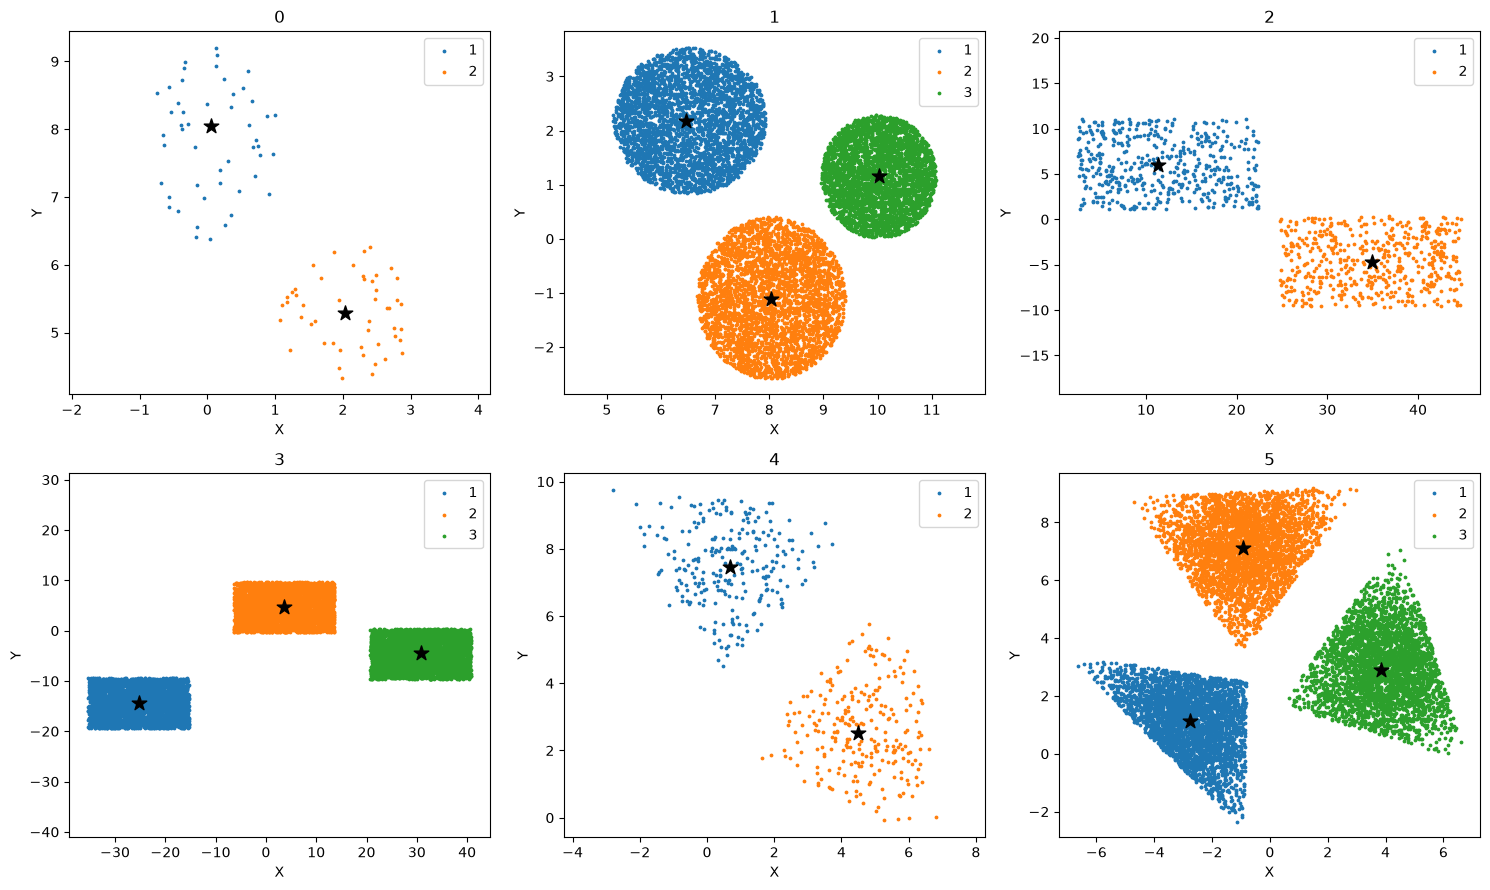

In [5]:
plt.figure(figsize=(15, 9))
for i, a in enumerate(d):
    plt.subplot(2, 3, i + 1)
    for j in np.unique(l[i]):
        b = a[l[i] == j]
        plt.scatter(b[:, 0], b[:, 1], s=3, label=str(j + 1))
    plt.scatter(c[i][:, 0], c[i][:, 1], c='black', marker='*', s=120)
    plt.title(str(i))
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.axis('equal')
    plt.legend()
plt.tight_layout()
plt.show()

# Кластеризация (0.75 за каждый алгоритм на всех данных)

На предложенных распределениях данных проверьте предложенные алгоритмы. Постройте графики кластеризации для каждой пары алгоритм-данные, разные кластеры покрасьте разным цветом. Воспользуйтесь sklearn реализациями. Параметры кластеризации для разных алгоритмов подберите такие, чтобы алгоритмы можно было сравнивать (по возможности одинаковое количество кластеров и т.д.)

In [6]:
np.random.seed(0)
a = mb(n_samples=1500, random_state=170)[0]
d = [
    mc(n_samples=1500, factor=0.5, noise=0.05, random_state=0)[0],
    mm(n_samples=1500, noise=0.05, random_state=0)[0],
    mb(n_samples=1500, cluster_std=[1, 2.5, 0.5], random_state=170)[0],
    a @ np.array([[0.6, -0.6], [-0.4, 0.8]]),
    mb(n_samples=1500, random_state=8)[0],
    np.random.rand(1500, 2)
]
t = ['Кольца', 'Полумесяцы', 'Разная дисперсия',
     'Вытянутые группы', 'Обычные группы', 'Без структуры']
p = [(2, 0.3, 20), (2, 0.3, 20), (3, 0.25, 15),
     (3, 0.15, 20), (3, 0.3, 20), (3, 0.3, 20)]

Кольца KMeans кластеров: 2 шум: 0
Кольца DBSCAN кластеров: 2 шум: 0
Полумесяцы KMeans кластеров: 2 шум: 0
Полумесяцы DBSCAN кластеров: 2 шум: 0
Разная дисперсия KMeans кластеров: 3 шум: 0
Разная дисперсия DBSCAN кластеров: 3 шум: 68
Вытянутые группы KMeans кластеров: 3 шум: 0
Вытянутые группы DBSCAN кластеров: 3 шум: 125
Обычные группы KMeans кластеров: 3 шум: 0
Обычные группы DBSCAN кластеров: 3 шум: 0
Без структуры KMeans кластеров: 3 шум: 0
Без структуры DBSCAN кластеров: 1 шум: 0


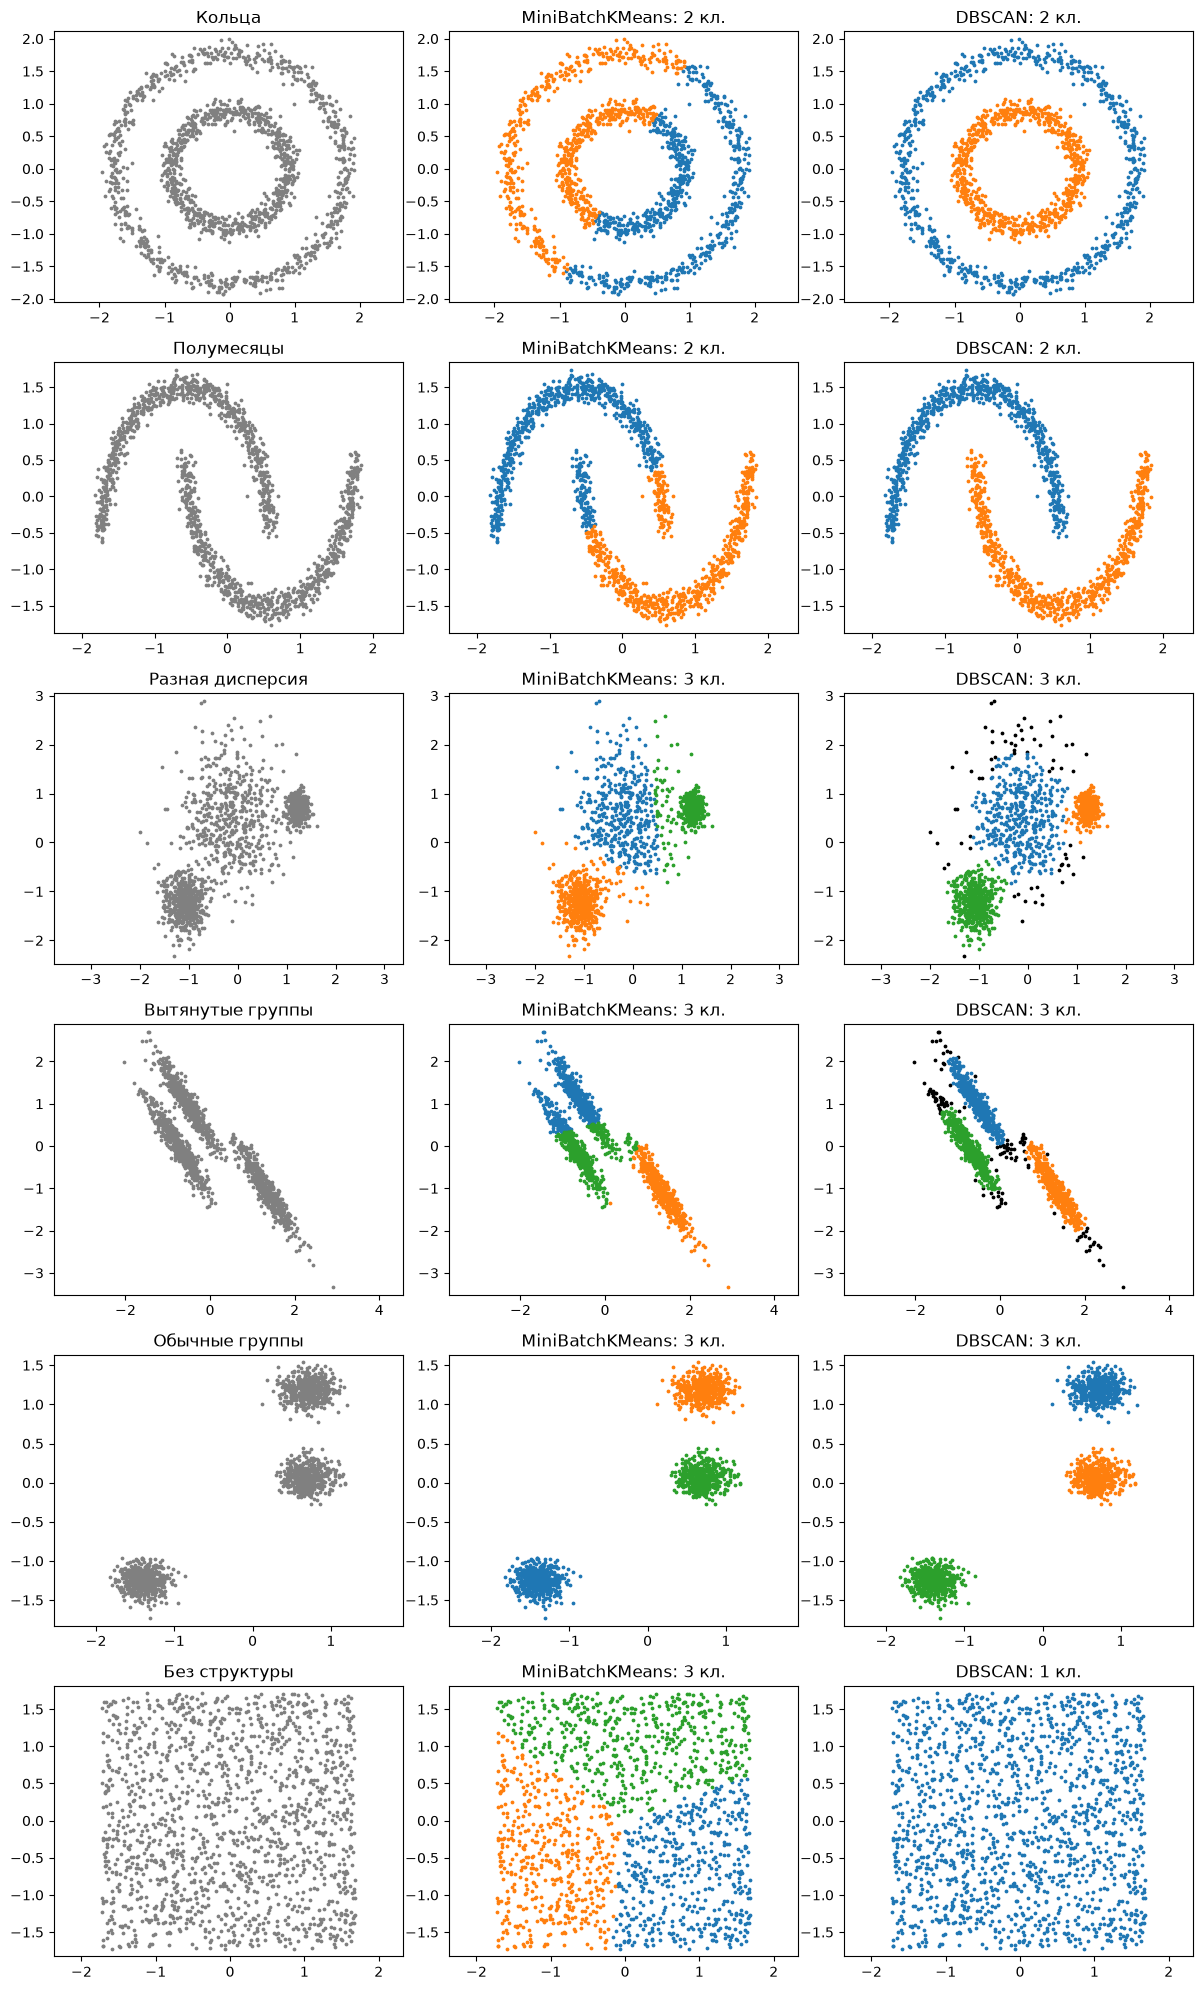

In [7]:
plt.figure(figsize=(12, 20))
for i, a in enumerate(d):
    a = SS().fit_transform(a)
    k, e, m = p[i]
    plt.subplot(6, 3, i * 3 + 1)
    plt.scatter(a[:, 0], a[:, 1], s=3, c='gray')
    plt.title(t[i])
    plt.axis('equal')
    for j, b in enumerate([KM(n_clusters=k, random_state=0, n_init=10, batch_size=256),
                           DB(eps=e, min_samples=m)]):
        z = b.fit_predict(a)
        plt.subplot(6, 3, i * 3 + j + 2)
        for h in np.unique(z):
            plt.scatter(a[z == h, 0], a[z == h, 1], s=3,
                        color='black' if h == -1 else plt.get_cmap('tab10')(int(h) % 10))
        plt.title(('MiniBatchKMeans' if j == 0 else 'DBSCAN') +
                  ': ' + str(len(set(z) - {-1})) + ' кл.')
        plt.axis('equal')
        print(t[i], 'KMeans' if j == 0 else 'DBSCAN',
              'кластеров:', len(set(z) - {-1}), 'шум:', np.sum(z == -1))
plt.tight_layout()
plt.show()